# CellCharter Benchmarking

- **Creator**: Sebastian Birk (<sebastian.birk@helmholtz-munich.de>)
- **Date of Creation:** 11.03.2024
- **Date of Last Modification:** 02.04.2026 (Sebastian Birk; <sebastian.birk@helmholtz-munich.de>)

- The CellCharter source code is available at https://github.com/CSOgroup/cellcharter.
- The corresponding publication is "Varrone, M., Tavernari, D., Santamaria-Martínez, A., Walsh, L. A. & Ciriello, G. CellCharter reveals spatial cell niches associated with tissue remodeling and cell plasticity. Nat. Genet. 56, 74–84 (2024)".
- The workflow of this notebook follows the tutorial from https://cellcharter.readthedocs.io/en/latest/notebooks/cosmx_human_nsclc.html.

- Run this notebook in the cellcharter environment, installable from ```('../../../envs/environment_cellcharter.yaml')```.

## 1. Setup

### 1.1 Import Libraries

In [70]:
%load_ext autoreload
%autoreload 2

In [71]:
import sys
sys.path.append("../../utils")

In [1]:
import warnings
import os

import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)
scvi.settings.seed = 12345

Seed set to 12345
Seed set to 12345


In [89]:
import matplotlib as mpl

In [92]:
import sklearn.metrics as skm
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent

In [73]:
from analysis_utils import *
from benchmarking_utils import max_overlap_plot

### 1.2 Configure Paths

In [2]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [75]:
n_pcs = None
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'

### 1.4 Run Notebook Setup

In [4]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [5]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [6]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [7]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

/tmp/ipykernel_1990876/3043166597.py:3: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(


In [8]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/cellcharter', exist_ok=True)

## 1.5 Define Functions

In [9]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs: int | None,
                             radius: float | None,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs: int | None = None,
                             radius: float | None = None,
                             delaunay: bool = True,
                             include_self_loop: bool = False,
                             batch_key: str | None = None,
                             compute_neighbor_counts: bool = False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. CellCharter Model

In [10]:
# Define dataset params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
batch_key = 'batch'
label_keys = [niche_key]
spot_sizes = [100, 20]

In [11]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_1990876/3735239799.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [12]:
sc.pp.filter_genes(adata, min_counts=3)
sc.pp.filter_cells(adata, min_counts=3)

In [13]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)

In [14]:
scvi.model.SCVI.setup_anndata(
    adata, 
    layer="counts", 
    batch_key=batch_key,
)

model = scvi.model.SCVI(adata)

In [15]:
model.train(early_stopping=True, enable_progress_bar=True)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/93 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=93` reached.


In [16]:
adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

In [18]:
embedding_key = 'X_cellcharter'

In [19]:
adata.obsm['spatial_fov'] = adata.obsm['spatial']

In [24]:
adata.obs[batch_key] = adata.obs[batch_key].astype('category')

In [25]:
sq.gr.spatial_neighbors(adata, library_key=batch_key, coord_type='generic', delaunay=True, spatial_key='spatial_fov', percentile=99)

INFO     Creating graph using `generic` coordinates and `None` transform and `2` libraries.                        


In [26]:
cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='sample')

  0%|          | 0/4 [00:00<?, ?it/s]

In [27]:
# Save updated AnnData
for col in adata.obs.columns:
    if isinstance(adata.obs[col].dtype, pd.CategoricalDtype):
        adata.obs[col] = adata.obs[col].astype(str).astype('category')

adata.obs['cell_id'] = adata.obs['cell_id'].astype(str)
adata.obs.index = adata.obs.index.astype(str)

def fix_arrow_strings(df):
    for col in df.columns:
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            df[col] = df[col].astype(str).astype('category')
        elif isinstance(df[col].array, pd.arrays.ArrowExtensionArray):
            df[col] = df[col].astype(str)
    df.index = df.index.astype(str)
    return df

adata.obs = fix_arrow_strings(adata.obs)
adata.var = fix_arrow_strings(adata.var)

adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_embedded.h5ad')

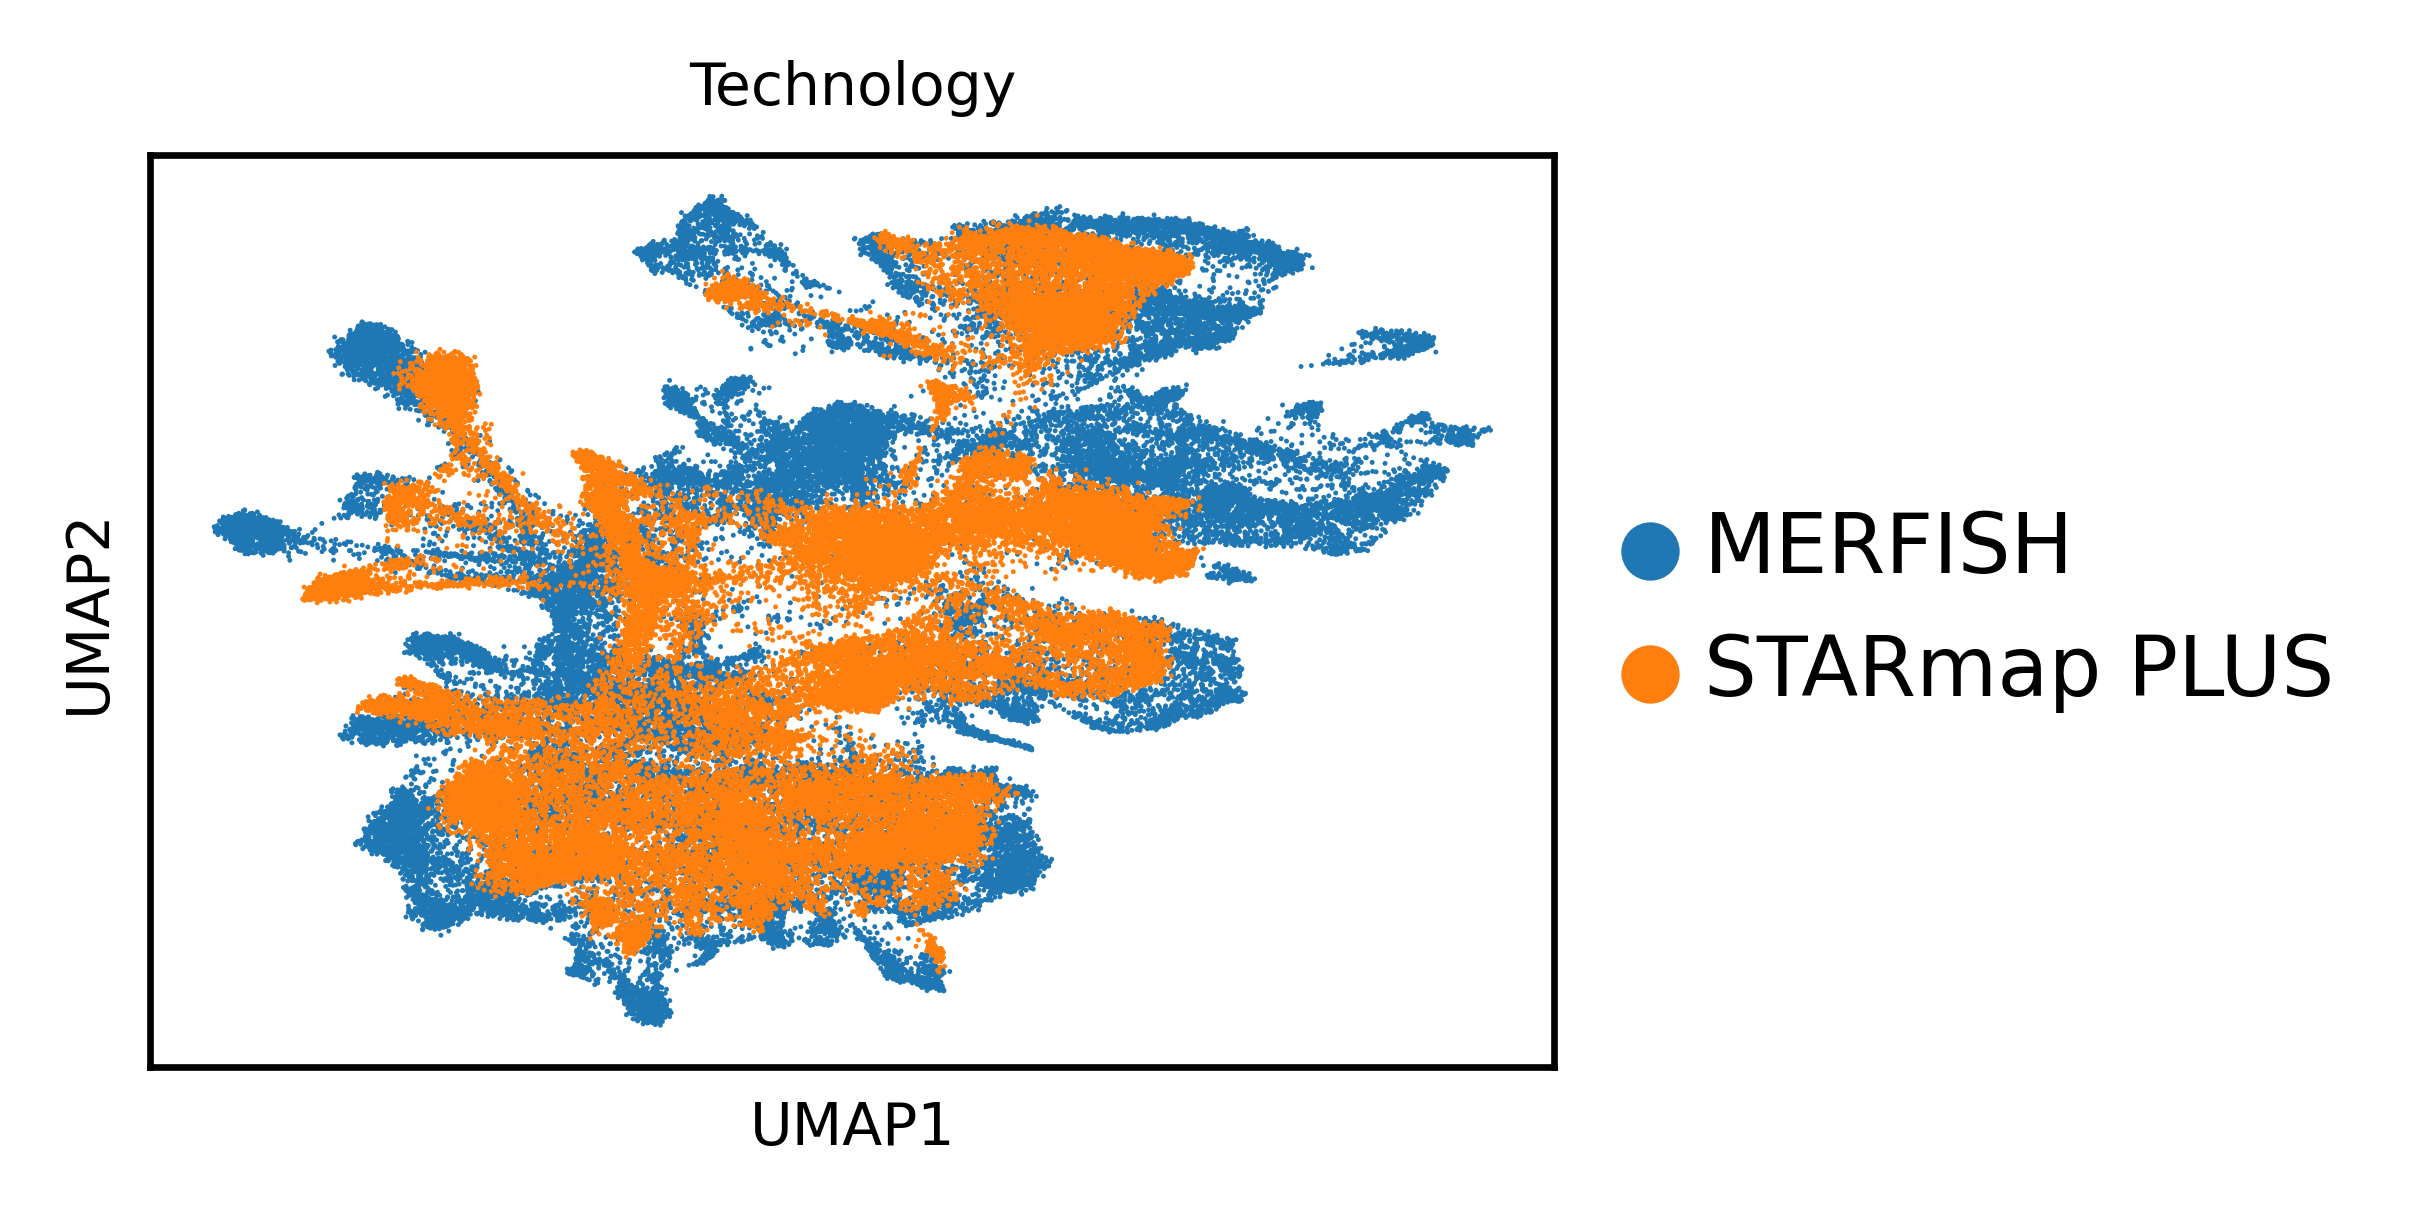

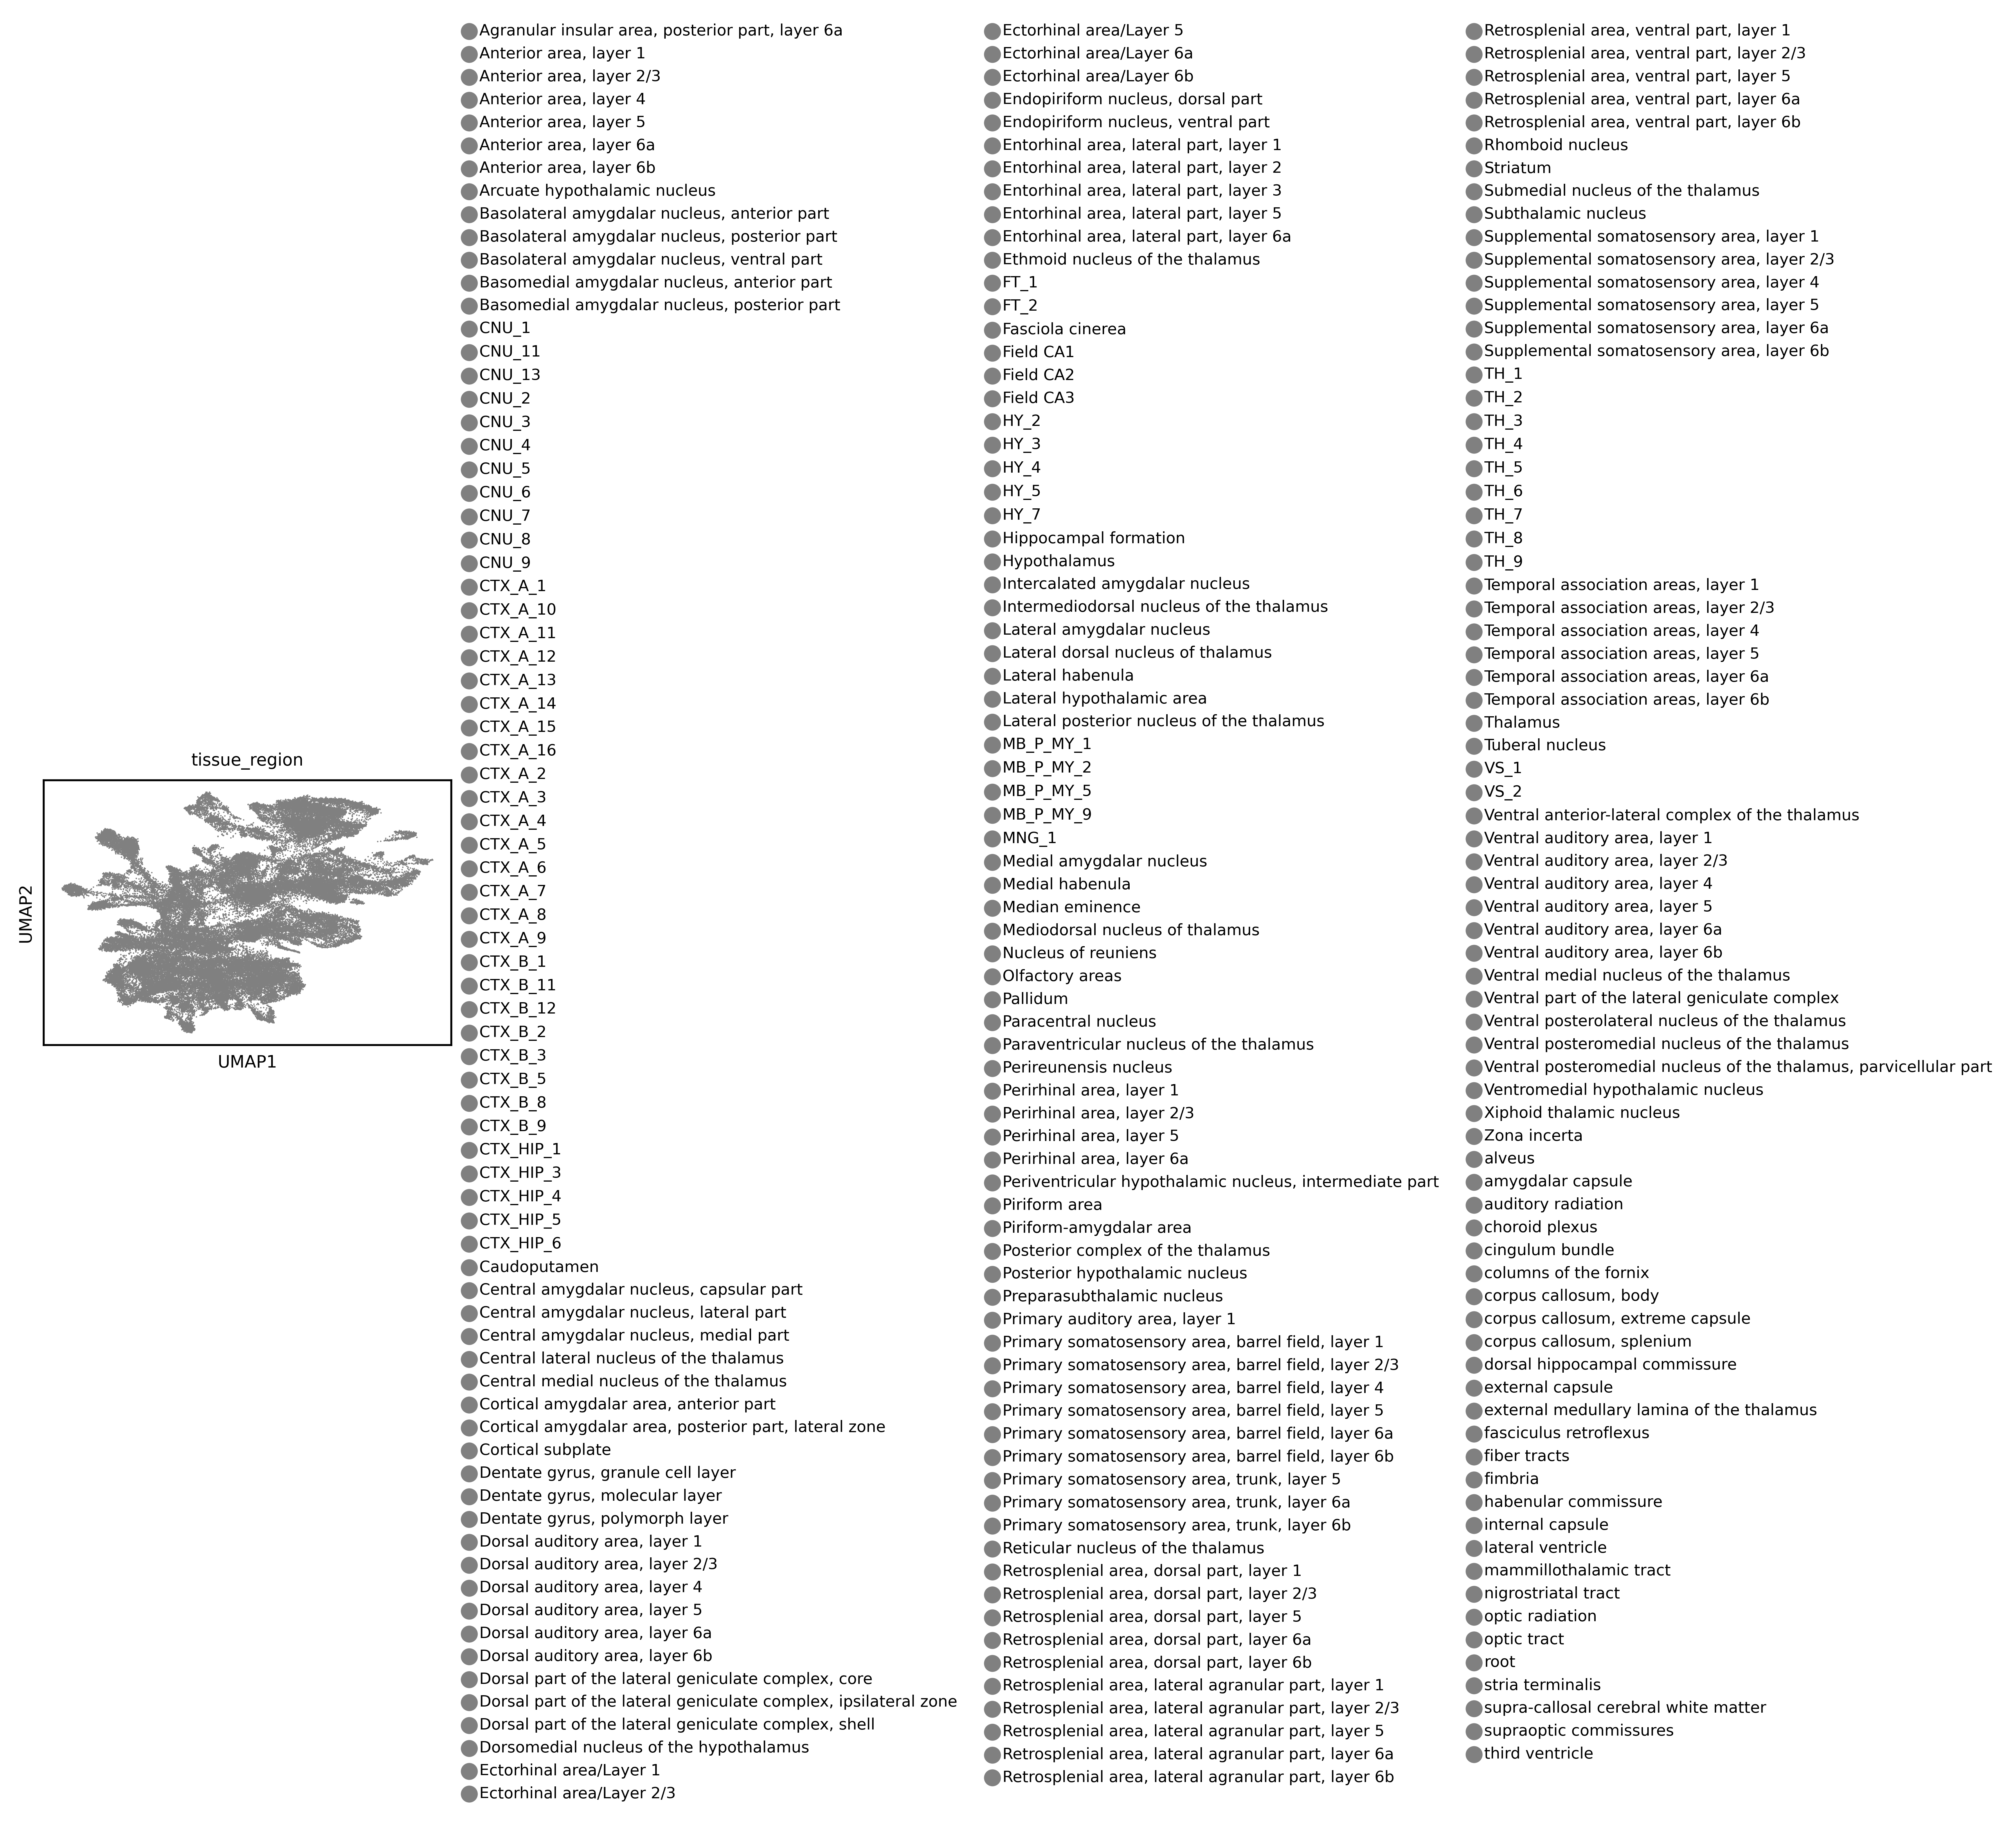

In [28]:
for emb_key in [embedding_key]:
    try:
        rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                         n_pcs=n_pcs, key_added=emb_key)
        rsc.tl.umap(adata, neighbors_key=emb_key)
    except NameError:
        sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                        n_pcs=n_pcs, key_added=emb_key)
        sc.tl.umap(adata, neighbors_key=emb_key)

    n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
    categories = adata.obs[batch_key].cat.categories.tolist()
    assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
    rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
    adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

    sc.pl.umap(
        adata,
        color=batch_key,
        title="Technology",
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

    for label_key in label_keys:
        sc.pl.umap(adata, color=label_key, show=False)
        for collection in plt.gca().collections:
            collection.set_rasterized(True)
        plt.savefig(
            f"{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
            format="svg", bbox_inches="tight"
        )
        plt.show()
        plt.close()

In [29]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_embedded.h5ad')

print(f"Embeddings saved to {f'{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_embedded.h5ad'} in obsm['{embedding_key}']")

Embeddings saved to /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/cellcharter/mmb0-1b_smb1-1b_1p_embedded.h5ad in obsm['X_cellcharter']


In [30]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_embedded.h5ad')

In [81]:
latent_leiden_resolution = 0.8

In [82]:
# Plot embedding-based clusters
for emb_key in [embedding_key]:
    latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
    
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=latent_leiden_resolution,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=latent_cluster_key,
                     resolution=latent_leiden_resolution,
                     flavor="igraph",
                     n_iterations=2)

In [83]:
adata.obs[latent_cluster_key].value_counts()

X_cellcharter_clusters_res_0.8
6     6999
2     6512
16    6307
0     5888
11    5064
3     4830
13    4420
10    4409
4     3651
24    3380
9     3240
15    2991
7     2934
22    2685
18    2649
17    2341
14    2339
21    1890
1     1639
5     1332
30    1186
12    1166
23    1161
29    1068
28     998
25     965
27     820
19     732
8      714
20     641
31     501
26     252
Name: count, dtype: int64

/tmp/ipykernel_1990876/1369466181.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


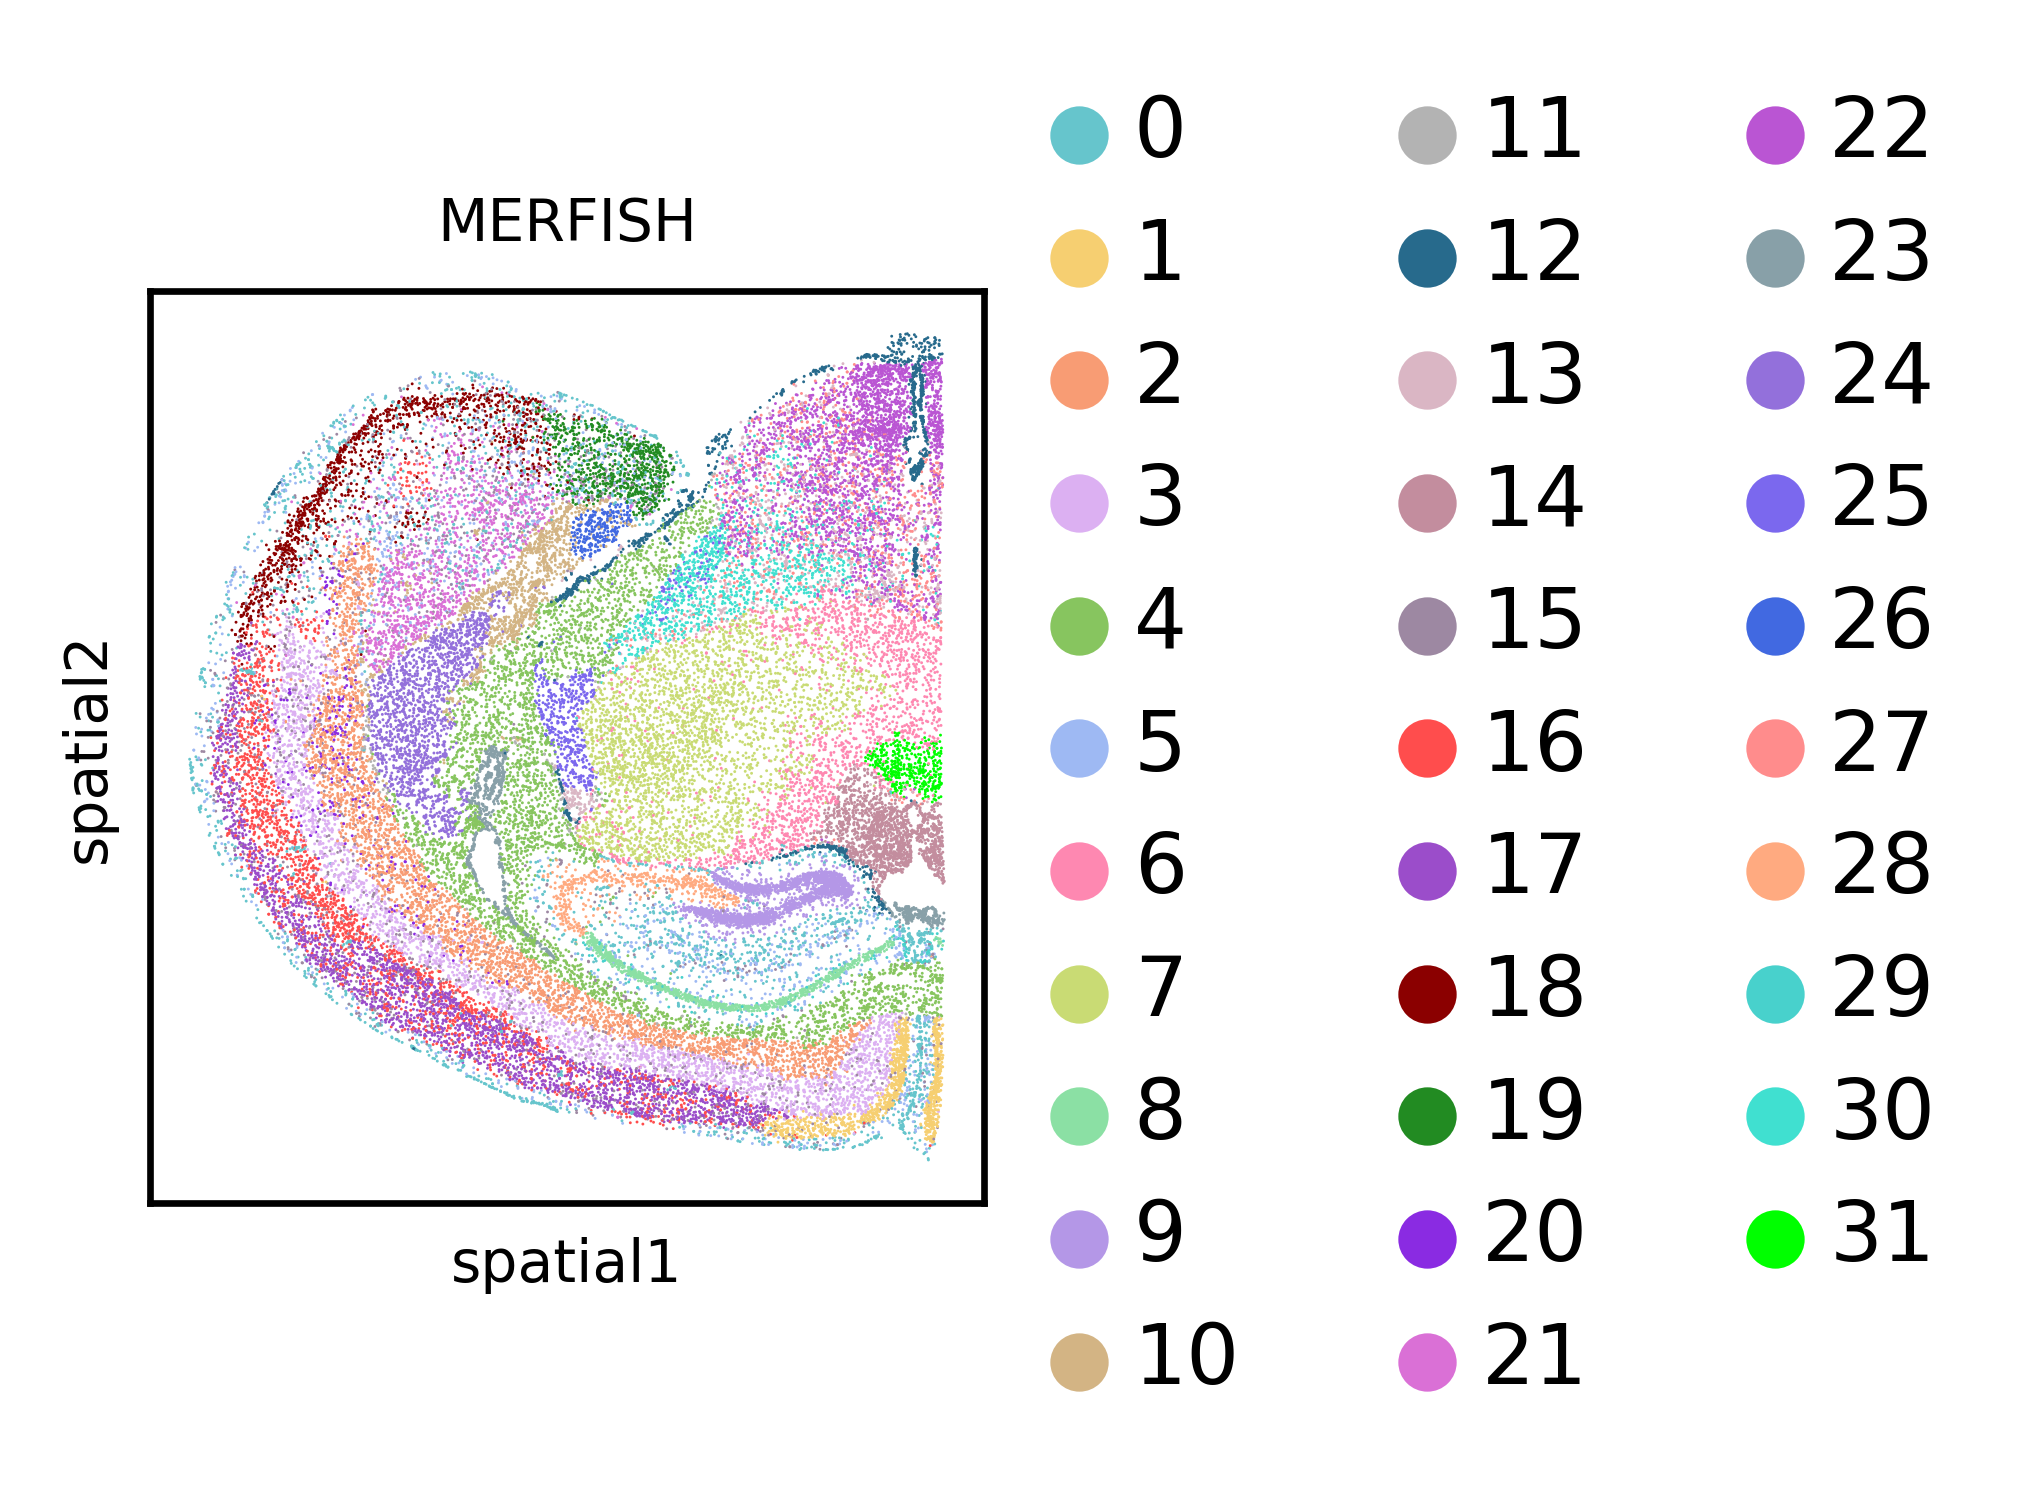

/tmp/ipykernel_1990876/1369466181.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


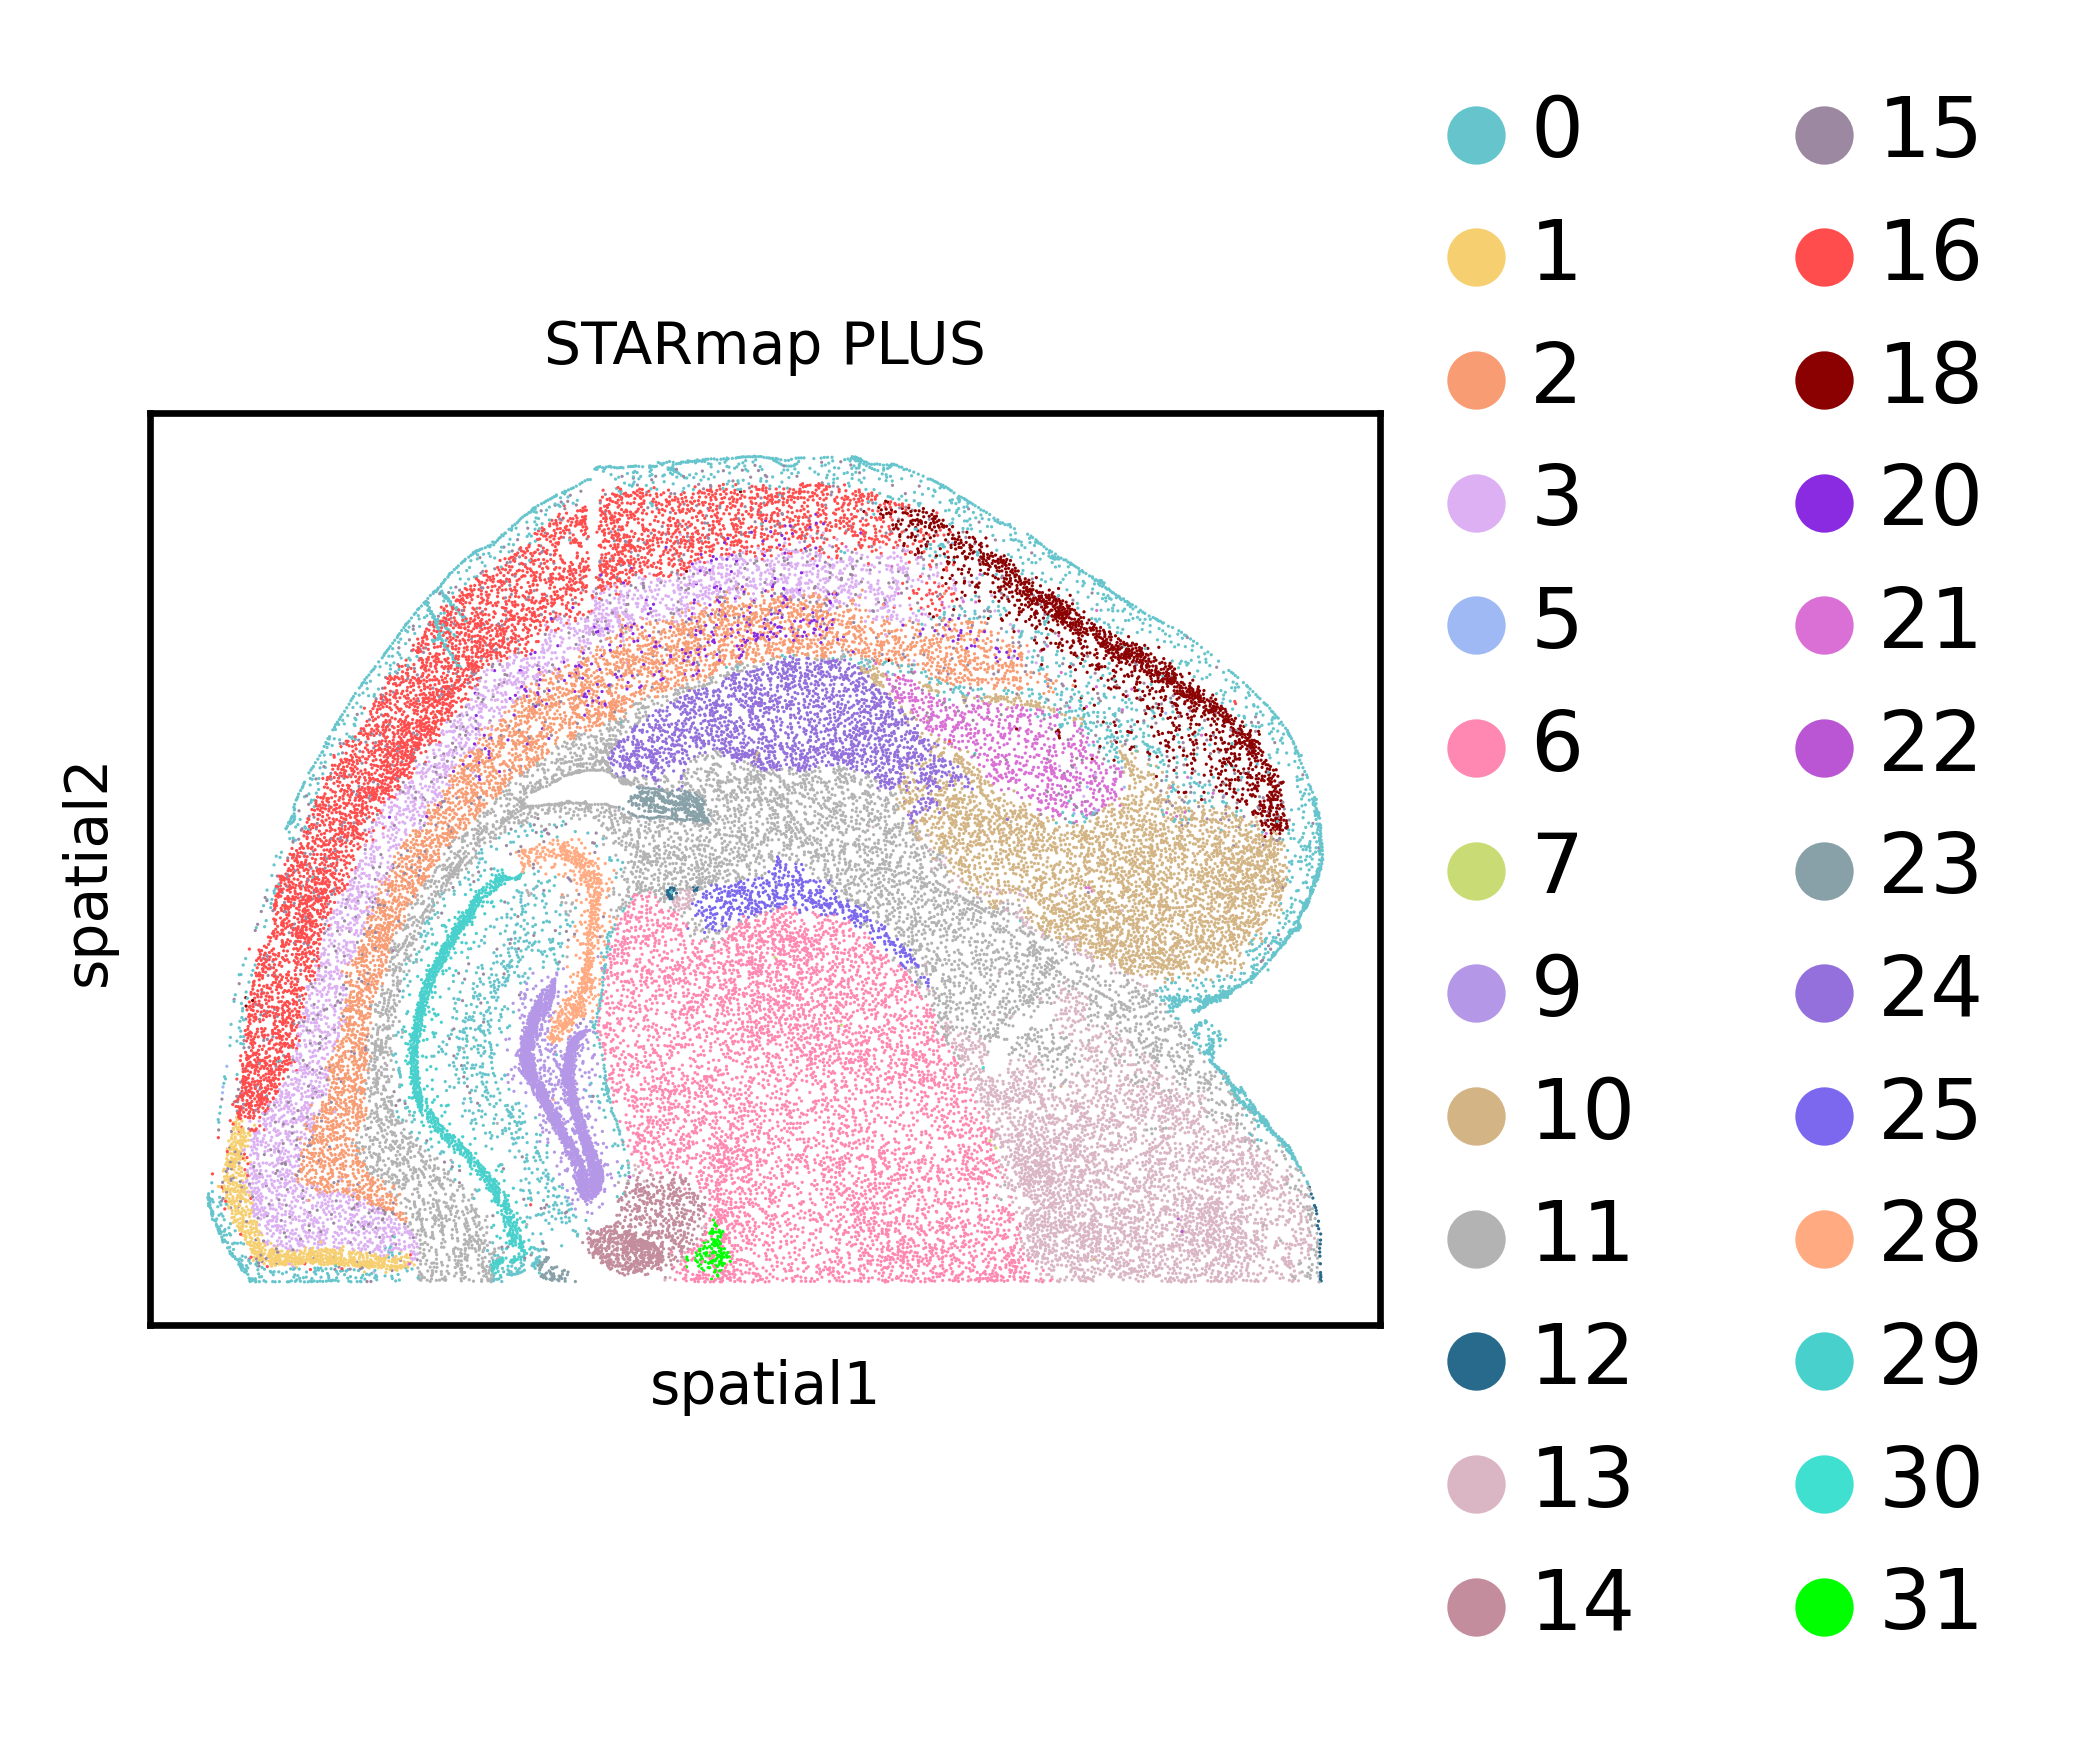

In [90]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/cellcharter/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [93]:
# Compute NMI with region annotations
mask = adata.obs["Sub_molecular_tissue_region"].notna()
labels_true = adata.obs.loc[mask, "Sub_molecular_tissue_region"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (Sub_molecular_tissue_region): {nmi:.4f}")

mask = adata.obs["ccf_region_name"].notna()
labels_true = adata.obs.loc[mask, "ccf_region_name"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (ccf_region_name): {nmi:.4f}")

NMI (Sub_molecular_tissue_region): 0.4602
NMI (ccf_region_name): 0.4383


In [97]:
# Compute iLISI
batch_key = "batch"
batch = adata.obs[batch_key].values

knn = pynndescent(adata.obsm[embedding_key], n_neighbors=90)
score = ilisi_knn(knn, batch)
print(f"iLISI ({embedding_key}): {score:.4f}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


iLISI (X_cellcharter): 0.0277


In [2]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/cellcharter/{dataset_name}_embedded_clustered.h5ad')

NameError: name 'adata' is not defined